# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 35: Análise Exploratória das Frequências LOFAR — MEDIUM Acertadas × Erradas

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

**Tarefa 1 (reunião de 26/10/2026)**, segunda classe. Em `35_eda_lofar_large.ipynb`, as LARGE acertadas têm uma **banda larga em ~31–86 Hz**, e as LARGE sem essa banda são confundidas com SMALL e MEDIUM. Aqui repetimos a análise para MEDIUM.

**Diferença em relação ao notebook das LARGE.** Os erros das MEDIUM se dividem entre classes diferentes (SMALL 61,9%, LARGE 32,9%, BACKGROUND 5,2%). Se juntarmos todas as erradas, assinaturas opostas podem se cancelar. Por isso as erradas são separadas pelo **destino**: a classe em que a gravação é prevista na maioria dos folds.

**Hipótese fixada antes de olhar esta classe:** as MEDIUM previstas como LARGE têm a banda de 31–86 Hz das LARGE, e menos conteúdo em 100–150 Hz. Os navios das MEDIUM são outros, não entraram na análise das LARGE (a classe é definida pelo comprimento), então este é um teste **fora da amostra**.

**Dados e cuidados:** os mesmos do notebook das LARGE: LOFAR do pipeline sem normalização (`lofar_bc15…`), espectro médio por gravação, testes por navio com FDR; e a extração **lofar1hz** (faixas de 0,98 Hz) para separar banda larga de raias. Valores abaixo de ~150 Hz devem ser lidos com cautela (borda do TPSW); a comparação entre grupos continua válida.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, false_discovery_control
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 2); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

CLASSE = 'MEDIUM'
CLS = dict(enumerate(R.CLASSES)); CID = {v: k for k, v in CLS.items()}
C = CID[CLASSE]
MODELO = 'cnn_lofar'                                    # CNN LOFAR do artigo (test_scripts/cnn_lofar.py)
OUTROS = {'MLP LOFAR': 'mlp_lofar', 'SVM LOFAR': 'svm_nystroem_6000_lofar_elasticnet_l1r0.15'}
LOFAR_DIR = os.path.join(R.ROOT, 'data', 'iara_processed', 'lofar_bc1559516c522e2b993895bf5cb2ac94')
CACHE = os.path.join(R.ROOT, 'data', 'iara_processed', 'cache_lofar_espectro_medio.pkl')

# Eixo de frequência do LOFAR do pipeline (src/iara/processing/analysis.py): fs = 48 kHz / decimação 3 = 16 kHz,
# nfft = 2 * n_pts = 2048, sem o bin DC -> 1024 faixas de 7,8125 Hz, de 7,8 Hz a 8 kHz
FS, NFFT = 16000, 2048
F = (np.arange(1024) + 1) * FS / NFFT

if os.path.exists(CACHE):
    S = pd.read_pickle(CACHE)
else:
    ids = sorted(int(f[:-4]) for f in os.listdir(LOFAR_DIR) if f.endswith('.pkl'))
    S = pd.DataFrame({i: pd.read_pickle(os.path.join(LOFAR_DIR, f'{i}.pkl'))['df'].values.mean(0) for i in ids}).T
    S.index.name = 'ID'; S.to_pickle(CACHE)

meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta['Ship ID'] = meta['Ship ID'].str.strip()
meta['Length'] = pd.to_numeric(meta['Length'], errors='coerce')
meta = meta.set_index(meta.ID.astype(int))
print(f'{len(S)} gravações com LOFAR; {len(F)} faixas de {F[0]:.4f} Hz')

1706 gravações com LOFAR; 1024 faixas de 7.8125 Hz


## 0. Rótulos de acerto e erro, e destino dos erros

Mesmo critério das LARGE: **acertada** = acerta em todos os folds de teste da CNN LOFAR do artigo; **errada** = erra em todos; **oscila** = o resto (fora do contraste).

In [2]:
def taxa_acerto(exp, c):
    # fração dos folds de teste em que a gravação da classe c foi acertada (voto majoritário por gravação)
    d = pd.concat(R.file_predictions(exp).values()); d = d[d.Target == c]
    t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean()); t.index = t.index.astype(int)
    return t

def grupo(t):
    return np.where(t == 1, 'acertada', np.where(t == 0, 'errada', 'oscila'))

T = pd.DataFrame({'CNN LOFAR': taxa_acerto(MODELO, C), **{k: taxa_acerto(v, C) for k, v in OUTROS.items()}})
T['grupo'] = grupo(T['CNN LOFAR'])
todos = T[['CNN LOFAR'] + list(OUTROS)]
T['consenso'] = np.where((todos == 1).all(1), 'acertada', np.where((todos == 0).all(1), 'errada', 'outro'))
T = T.join(meta[['Ship ID', 'Dataset', 'DETAILED TYPE', 'Length']])

# rótulo verdadeiro de todas as gravações (para os espectros de referência das outras classes)
LAB = pd.concat(R.file_predictions(MODELO).values()).groupby('File').Target.first(); LAB.index = LAB.index.astype(int)

# destino dos erros (todas as predições erradas da classe, gravação × fold)
_d = pd.concat(R.file_predictions(MODELO).values()); _d = _d[(_d.Target == C) & (_d.Prediction != C)]
DESTINO = (_d.Prediction.map(CLS).value_counts(normalize=True) * 100).round(1)

CONT = pd.DataFrame({'CNN LOFAR': T.grupo.value_counts(), 'consenso CNN+MLP+SVM': T.consenso.value_counts()}).fillna(0).astype(int)
POR_DS = pd.crosstab(T.Dataset, T.grupo, margins=True, margins_name='total')
POR_DS['% errada'] = (100 * POR_DS['errada'] / POR_DS['total']).round(1)
N_NAVIOS = T['Ship ID'].nunique()
_sh = T[T.grupo != 'oscila'].groupby('Ship ID').grupo.nunique()
N_NAVIOS_MISTOS = int((_sh > 1).sum())
print(f'{CLASSE}: {len(T)} gravações de {N_NAVIOS} navios'); display(CONT)
print('Destino dos erros da CNN LOFAR (%):'); display(DESTINO.to_frame('%'))
print('Grupos por subconjunto de gravação:'); display(POR_DS)
print('Comprimento (m) por grupo:'); display(T.groupby('grupo').Length.describe()[['count', '25%', '50%', '75%']].round(0))

/tmp/ipykernel_64106/2548822792.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean()); t.index = t.index.astype(int)


/tmp/ipykernel_64106/2548822792.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean()); t.index = t.index.astype(int)


MEDIUM: 397 gravações de 82 navios


/tmp/ipykernel_64106/2548822792.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean()); t.index = t.index.astype(int)


,CNN LOFAR,consenso CNN+MLP+SVM
acertada,193,142
errada,75,47
oscila,129,0
outro,0,208


Destino dos erros da CNN LOFAR (%):


,%
Prediction,
SMALL,61.9
LARGE,32.9
BACKGROUND,5.2


Grupos por subconjunto de gravação:


grupo,acertada,errada,oscila,total,% errada
Dataset,,,,,
A,76,17,27,120,14.2
B,33,13,27,73,17.8
C,30,23,22,75,30.7
D,54,22,53,129,17.1
total,193,75,129,397,18.9


Comprimento (m) por grupo:


,count,25%,50%,75%
grupo,,,,
acertada,193.0,72.0,72.0,75.0
errada,75.0,72.0,76.0,84.0
oscila,129.0,72.0,81.0,88.0


In [3]:
def por_navio(ids):
    # média das gravações de cada navio: cada navio conta uma vez em cada grupo
    return S.loc[ids].groupby(T.loc[ids, 'Ship ID'].values).mean()

def teste_faixas(ids_a, ids_e):
    A, E = por_navio(ids_a), por_navio(ids_e)
    U = np.array([mannwhitneyu(E.iloc[:, k], A.iloc[:, k]).statistic for k in range(S.shape[1])])
    p = np.array([mannwhitneyu(E.iloc[:, k], A.iloc[:, k]).pvalue for k in range(S.shape[1])])
    q = false_discovery_control(p)
    return pd.DataFrame({'f (Hz)': F, 'acertada': A.mean().values, 'errada': E.mean().values,
                         'Δ (errada − acertada)': E.mean().values - A.mean().values,
                         'AUC': U / (len(A) * len(E)), 'q (FDR)': q}), len(A), len(E)

In [4]:
# destino de cada gravação errada: a classe mais prevista nos folds em que ela foi teste
_d = pd.concat(R.file_predictions(MODELO).values()); _d = _d[_d.Target == C].copy(); _d['File'] = _d.File.astype(int)
_dest = _d[_d.Prediction != C].groupby('File').Prediction.agg(lambda x: x.value_counts().index[0]).map(CLS)
T['destino'] = _dest.reindex(T.index)
T['subgrupo'] = np.where(T.grupo == 'errada', 'errada→' + T.destino.fillna('?'), T.grupo)
NAV_DEST = T[T.grupo == 'errada'].groupby('destino')['Ship ID'].nunique().sort_values(ascending=False)
DESTS = [d for d in NAV_DEST.index if NAV_DEST[d] >= 10]          # destinos com pelo menos 10 navios
SUBS = ['acertada'] + [f'errada→{d}' for d in DESTS]
RESUMO_SUB = T.groupby('subgrupo').agg(gravações=('grupo', 'size'), navios=('Ship ID', 'nunique'),
                                       comprimento_mediano=('Length', 'median'))
print('Subgrupos (errada→X = gravação sempre errada, prevista sobretudo como X):'); display(RESUMO_SUB)
print('Gravações por subconjunto:'); display(pd.crosstab(T.subgrupo, T.Dataset, margins=True, margins_name='total'))

# a classe é definida pelo comprimento: um navio não aparece em duas classes (os navios das outras classes são outros)
_cl = LAB.map(CLS).to_frame('classe').join(meta[['Ship ID']]).dropna()
_cl = _cl[_cl['Ship ID'].str.strip().isin(['', '-']) == False]
N_NAVIOS_COMUNS = int((_cl.groupby('Ship ID').classe.nunique() > 1).sum())
print(f'Navios presentes em mais de uma classe: {N_NAVIOS_COMUNS}')

Subgrupos (errada→X = gravação sempre errada, prevista sobretudo como X):


,gravações,navios,comprimento_mediano
subgrupo,,,
acertada,193,40,72.0
errada→BACKGROUND,4,4,86.0
errada→LARGE,35,27,77.0
errada→SMALL,36,24,74.5
oscila,129,49,81.0


Gravações por subconjunto:


Dataset,A,B,C,D,total
subgrupo,,,,,
acertada,76,33,30,54,193
errada→BACKGROUND,0,1,0,3,4
errada→LARGE,10,5,13,7,35
errada→SMALL,7,7,10,12,36
oscila,27,27,22,53,129
total,120,73,75,129,397


Navios presentes em mais de uma classe: 0


**Leitura.**
- 397 gravações MEDIUM de 82 navios: 193 acertadas, 129 oscilam e 75 erradas. As MEDIUM oscilam muito mais que as LARGE: a classe é mais difícil.
- Destino dos erros: SMALL 61,9%, LARGE 32,9%, BACKGROUND 5,2%. Subgrupos analisados (destinos com pelo menos 10 navios): **errada→LARGE**: 35 gravações de 27 navios; **errada→SMALL**: 36 gravações de 24 navios. Ficam de fora, por terem poucos navios: errada→BACKGROUND.
- A fração de erradas por subconjunto vai de 14,2% (A) a 30,7% (C).
- Nenhum navio aparece em mais de uma classe (0): os navios desta análise são independentes dos da análise das LARGE.

## 1. Espectro LOFAR médio por subgrupo

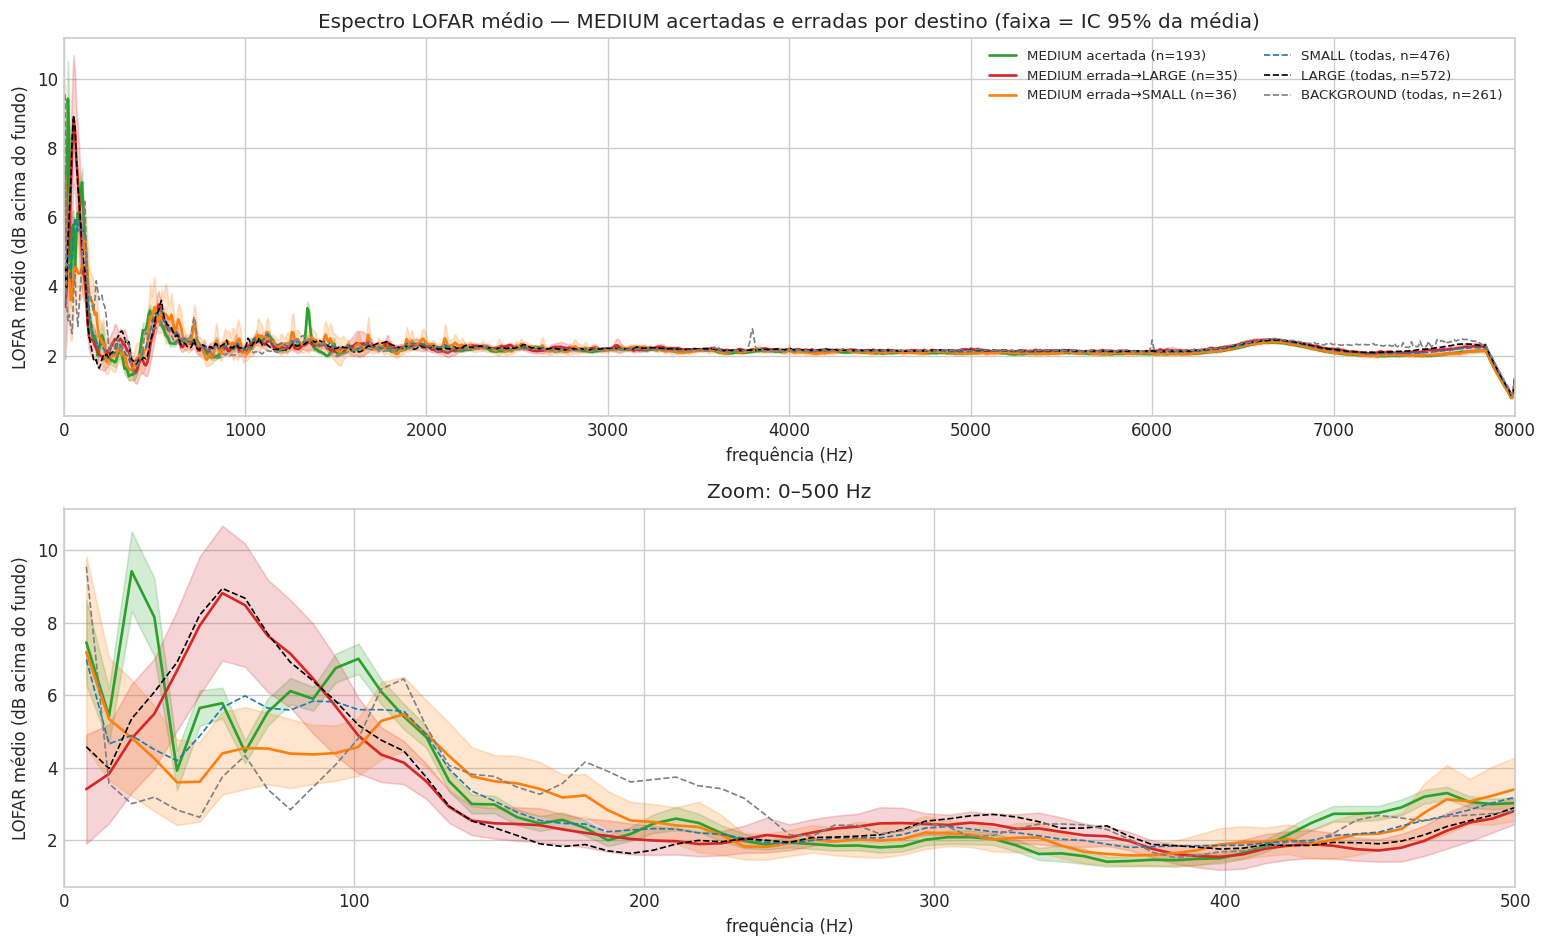

In [5]:
REF = {CLS[c]: S.loc[LAB.index[LAB == c]] for c in range(4) if c != C}
GS = {s: S.loc[T.index[T.subgrupo == s]] for s in SUBS}
cores_s = dict(zip(SUBS, ['tab:green', 'tab:red', 'tab:orange', 'tab:brown']))
cores_ref = {'SMALL': 'tab:blue', 'MEDIUM': 'tab:purple', 'LARGE': 'k', 'BACKGROUND': 'tab:gray'}
fig, ax = plt.subplots(2, 1, figsize=(13, 8))
for a, fmax in zip(ax, (8000, 500)):
    k = F <= fmax
    for s, X in GS.items():
        m, se = X.mean().values, X.std().values / np.sqrt(len(X))
        a.plot(F[k], m[k], color=cores_s[s], lw=1.6, label=f'{CLASSE} {s} (n={len(X)})')
        a.fill_between(F[k], (m - 1.96 * se)[k], (m + 1.96 * se)[k], color=cores_s[s], alpha=0.2)
    for c, X in REF.items():
        a.plot(F[k], X.mean().values[k], color=cores_ref[c], lw=1, ls='--', label=f'{c} (todas, n={len(X)})')
    a.set_xlabel('frequência (Hz)'); a.set_ylabel('LOFAR médio (dB acima do fundo)'); a.set_xlim(0, fmax)
ax[0].set_title(f'Espectro LOFAR médio — {CLASSE} acertadas e erradas por destino (faixa = IC 95% da média)')
ax[1].set_title('Zoom: 0–500 Hz'); ax[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

## 2. Diferença faixa a faixa, por destino

Mann-Whitney por faixa entre as erradas e as acertadas, com médias por navio e FDR, primeiro juntando todas as erradas e depois separando por destino:

Δ e AUC médios por banda (errada − acertada; médias por navio):


contraste,acertada × errada (todas),acertada × errada→LARGE,acertada × errada→SMALL
navios acertada,40.00,40.00,40.00
navios errada,44.00,27.00,24.00
"faixas com q < 0,05",0.00,42.00,0.00
abaixo de 1 kHz,0.00,12.00,0.00
acima de 1 kHz,0.00,30.00,0.00
Δ 0–31 Hz,0.02,-0.56,1.34
Δ 31–86 Hz,1.75,3.61,-0.07
Δ 86–150 Hz,-1.14,-1.63,-0.83
Δ 150–250 Hz,-0.10,-0.53,0.10
Δ 250–500 Hz,-0.06,-0.07,-0.01


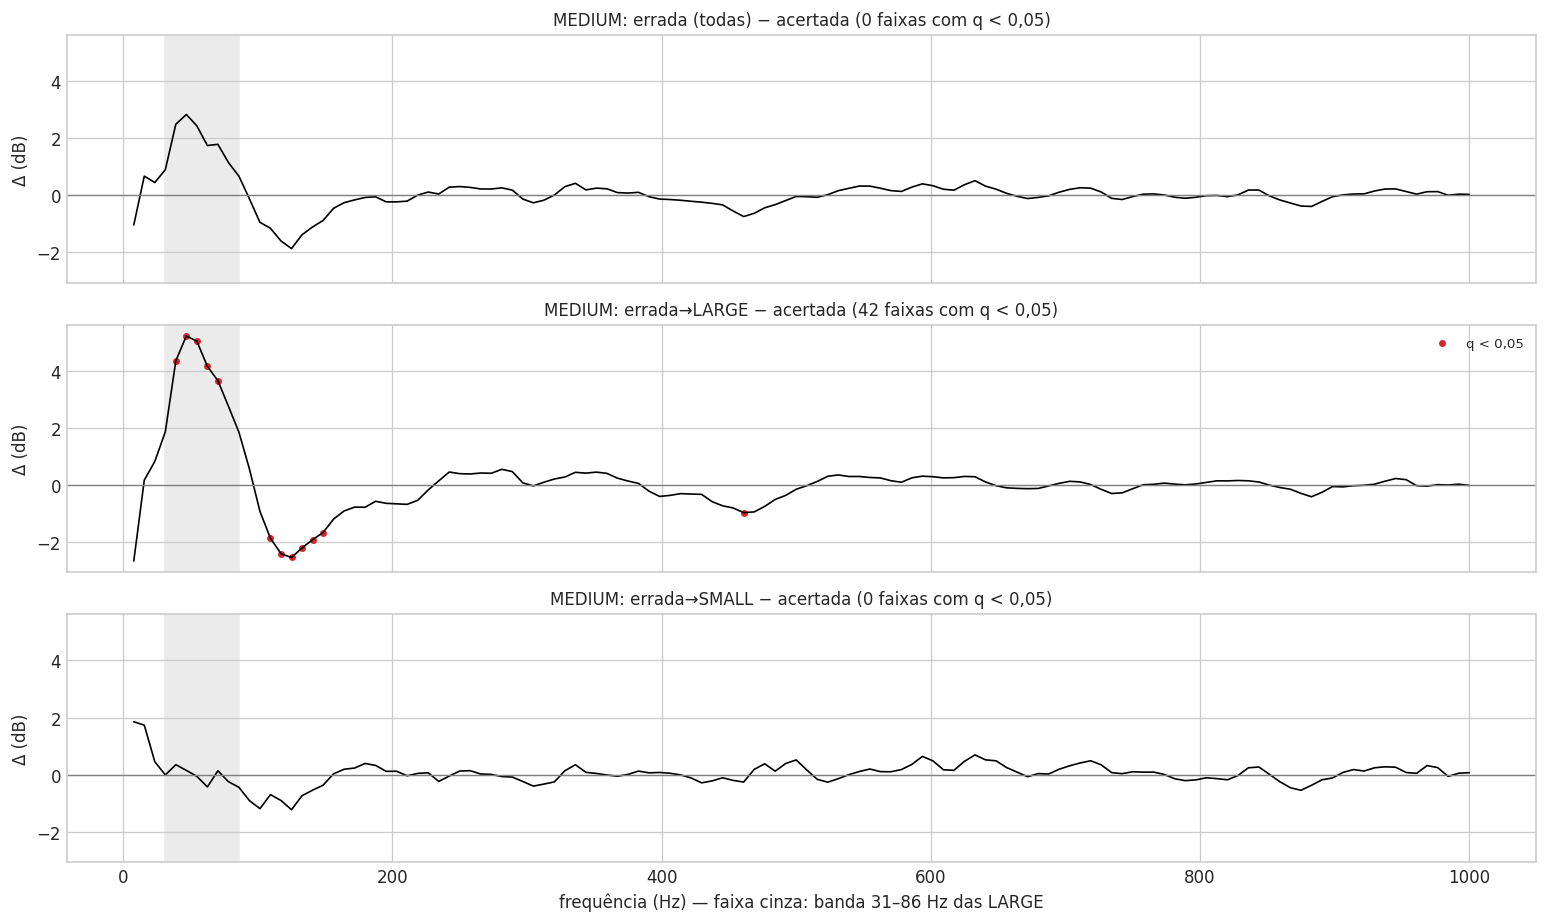

In [6]:
ia = T.index[T.subgrupo == 'acertada']
CONTRASTES = {'errada (todas)': T.index[T.grupo == 'errada'], **{f'errada→{d}': T.index[T.subgrupo == f'errada→{d}'] for d in DESTS}}
TFD, _rows = {}, []
FAIXAS_B = [0, 31, 86, 150, 250, 500, 1000, 2000, 4000, 8001]
for nome, ie in CONTRASTES.items():
    tf, na, ne = teste_faixas(ia, ie); tf['sig'] = tf['q (FDR)'] < 0.05; TFD[nome] = tf
    b = tf.groupby(pd.cut(tf['f (Hz)'], FAIXAS_B, right=False), observed=False)
    r = {'contraste': f'acertada × {nome}', 'navios acertada': na, 'navios errada': ne,
         'faixas com q < 0,05': int(tf.sig.sum()), 'abaixo de 1 kHz': int(tf[tf['f (Hz)'] < 1000].sig.sum()),
         'acima de 1 kHz': int(tf[tf['f (Hz)'] >= 1000].sig.sum())}
    r.update({f'Δ {iv.left}–{min(iv.right, 8000)} Hz': v for iv, v in b['Δ (errada − acertada)'].mean().items()})
    r.update({f'AUC {iv.left}–{min(iv.right, 8000)} Hz': v for iv, v in b['AUC'].mean().items()})
    _rows.append(r)
CONTR = pd.DataFrame(_rows).set_index('contraste')
print('Δ e AUC médios por banda (errada − acertada; médias por navio):'); display(CONTR.round(2).T)

fig, ax = plt.subplots(len(TFD), 1, figsize=(13, 2.6 * len(TFD)), sharex=True, sharey=True)
for a, (nome, tf) in zip(np.atleast_1d(ax), TFD.items()):
    k = tf['f (Hz)'] <= 1000
    a.plot(tf['f (Hz)'][k], tf['Δ (errada − acertada)'][k], color='k', lw=1)
    s_ = k & tf.sig
    a.scatter(tf['f (Hz)'][s_], tf['Δ (errada − acertada)'][s_], color='tab:red', s=10, label='q < 0,05')
    a.axhline(0, color='gray', lw=0.8); a.axvspan(31, 86, color='0.92', zorder=0)
    a.set_ylabel('Δ (dB)'); a.set_title(f'{CLASSE}: {nome} − acertada ({int(tf.sig.sum())} faixas com q < 0,05)', fontsize=10)
    if s_.any():
        a.legend(fontsize=8)
np.atleast_1d(ax)[-1].set_xlabel('frequência (Hz) — faixa cinza: banda 31–86 Hz das LARGE')
plt.tight_layout(); plt.show()

**Leitura.**
- **Juntando todas as erradas**, nenhuma faixa é significativa; 40 navios acertados e 44 errados.
- **errada→LARGE** (27 navios): 42 faixas com q < 0,05 (12 abaixo e 30 acima de 1 kHz); bandas que mais diferem: 31–86 Hz +3,6 dB (AUC 0,75), 86–150 Hz -1,6 dB (AUC 0,27).
- **errada→SMALL** (24 navios): 0 faixas com q < 0,05 (0 abaixo e 0 acima de 1 kHz).
- **errada→LARGE:** têm a **assinatura das LARGE**: mais conteúdo em 31–86 Hz e menos em 86–150 Hz; o espectro médio fica mais perto de LARGE (0,28 dB RMS).
- **errada→SMALL:** nenhuma faixa difere das acertadas no teste faixa a faixa; o espectro médio fica mais perto de SMALL (0,54 dB RMS); há um indício de vento mais forte.
- Juntas, as direções se misturam e o teste conjunto acha pouco: as erradas precisam ser vistas por destino.

## 3. Teste fora da amostra: a banda das LARGE

A banda de 31–86 Hz e a faixa de 100–150 Hz foram escolhidas na análise das LARGE, com outros navios. Aqui elas são só **medidas**, sem nenhuma escolha a partir dos dados desta classe. Para comparação, a mesma medida nas classes inteiras:

In [7]:
# Hipótese fixada ANTES de olhar esta classe: a banda 31–86 Hz que separa as LARGE acertadas das erradas (NB35 LARGE),
# e a faixa 100–150 Hz, onde as LARGE erradas tinham mais conteúdo. Os navios desta classe não entraram naquela análise.
BL, BC = (F >= 31) & (F < 86), (F >= 100) & (F < 150)
_kp = (F >= 20) & (F <= 250)
_pico = pd.Series(F[np.where(_kp)[0][S.values[:, _kp].argmax(1)]], index=S.index)
X = pd.DataFrame({'banda 31–86 Hz (dB)': S.loc[T.index, BL].mean(1), '100–150 Hz (dB)': S.loc[T.index, BC].mean(1),
                  'pico grave em 31–86 Hz': _pico.loc[T.index].between(31, 86, inclusive='left')}).join(T[['subgrupo', 'Ship ID']])
NAV = X.groupby(['subgrupo', 'Ship ID']).mean(numeric_only=True).reset_index()
_a = NAV[NAV.subgrupo == 'acertada']
_rows = []
for s in SUBS:
    x = NAV[NAV.subgrupo == s]
    r = {'subgrupo': f'{CLASSE} {s}', 'navios': len(x)}
    for c in ('banda 31–86 Hz (dB)', '100–150 Hz (dB)'):
        r[f'{c}: mediana'] = x[c].median()
        if s != 'acertada':
            U, p = mannwhitneyu(x[c], _a[c]); r[f'{c}: AUC vs acertada'] = U / (len(x) * len(_a)); r[f'{c}: p'] = p
    r['% gravações com pico em 31–86 Hz'] = 100 * X[X.subgrupo == s]['pico grave em 31–86 Hz'].mean()
    _rows.append(r)
for c in REF:
    ids = LAB.index[LAB == CID[c]]
    _rows.append({'subgrupo': f'{c} (todas)', 'navios': meta.loc[ids, 'Ship ID'].nunique() if c != 'BACKGROUND' else np.nan,
                  'banda 31–86 Hz (dB): mediana': S.loc[ids, BL].mean(1).median(), '100–150 Hz (dB): mediana': S.loc[ids, BC].mean(1).median(),
                  '% gravações com pico em 31–86 Hz': 100 * _pico.loc[ids].between(31, 86, inclusive='left').mean()})
APRIORI = pd.DataFrame(_rows).set_index('subgrupo')
display(APRIORI.round(3))

,navios,banda 31–86 Hz (dB): mediana,100–150 Hz (dB): mediana,% gravações com pico em 31–86 Hz,banda 31–86 Hz (dB): AUC vs acertada,banda 31–86 Hz (dB): p,100–150 Hz (dB): AUC vs acertada,100–150 Hz (dB): p
subgrupo,,,,,,,,
MEDIUM acertada,40.0,3.86,5.31,32.12,NaN,NaN,NaN,NaN
MEDIUM errada→LARGE,27.0,7.04,3.51,80.00,0.82,0.00,0.21,0.00
MEDIUM errada→SMALL,24.0,3.39,4.92,38.89,0.47,0.69,0.39,0.13
SMALL (todas),87.0,4.85,4.25,42.86,NaN,NaN,NaN,NaN
LARGE (todas),417.0,7.19,3.36,72.20,NaN,NaN,NaN,NaN
BACKGROUND (todas),NaN,1.45,4.40,23.75,NaN,NaN,NaN,NaN


**Leitura.**
- MEDIUM acertadas: banda 31–86 Hz com mediana 3,9 dB e 32% das gravações com o pico grave em 31–86 Hz.
- **errada→LARGE**: banda 31–86 Hz com mediana 7,0 dB (AUC 0,82, p < 0,001), 100–150 Hz com 3,5 dB (AUC 0,21, p < 0,001); 80% das gravações com o pico grave em 31–86 Hz; **errada→SMALL**: banda 31–86 Hz com mediana 3,4 dB (AUC 0,47, p = 0,693), 100–150 Hz com 4,9 dB (AUC 0,39, p = 0,132); 39% das gravações com o pico grave em 31–86 Hz.
- Nas classes inteiras, a fração de gravações com o pico grave em 31–86 Hz é: SMALL 43%, LARGE 72%.
- **A hipótese se confirma fora da amostra:** as MEDIUM previstas como LARGE têm a banda de 31–86 Hz no nível das LARGE (7,0 × 7,2 dB) e o pico grave na banda tão frequente quanto nas LARGE. Para o modelo, essa banda é uma pista de LARGE, e ela aparece também em navios MEDIUM (Seção 3.1).

### 3.1 A banda como pista do modelo

Para todas as gravações de navio: em que fração dos folds a CNN LOFAR prevê LARGE, conforme a gravação tenha ou não o pico grave em 31–86 Hz?

In [8]:
# A banda como pista do modelo: em que fração dos folds a gravação é prevista como LARGE, sem e com o pico grave
# (maior LOFAR médio entre 20 e 250 Hz) em 31–86 Hz? Só gravações de navio (sem BACKGROUND).
_kp = (F >= 20) & (F <= 250)
_pk = pd.Series(F[np.where(_kp)[0][S.values[:, _kp].argmax(1)]], index=S.index)
_dd = pd.concat(R.file_predictions(MODELO).values()); _dd['File'] = _dd.File.astype(int)
_t = _dd.assign(L=_dd.Prediction == CID['LARGE']).groupby('File').agg(L=('L', 'mean'), Target=('Target', 'first'))
_t = _t[_t.Target != CID['BACKGROUND']]
_t['banda'] = _pk.reindex(_t.index).between(31, 86, inclusive='left')
_t['classe'] = _t.Target.map(CLS)
BANDA_PREV = (100 * _t.groupby(['classe', 'banda']).L.mean().unstack()).rename(
    columns={False: '% prevista LARGE, sem a banda', True: '% prevista LARGE, com a banda'})
BANDA_PREV.columns.name = None
BANDA_PREV['% das gravações com a banda'] = 100 * _t.groupby('classe').banda.mean()
BANDA_PREV = BANDA_PREV.loc[['SMALL', 'MEDIUM', 'LARGE']]
FRAC_LARGE_BANDA = 100 * (_t[_t.banda].classe == 'LARGE').mean()
display(BANDA_PREV.round(1))
print(f'Das gravações de navio com a banda, {FRAC_LARGE_BANDA:.0f}% são LARGE.')

,"% prevista LARGE, sem a banda","% prevista LARGE, com a banda",% das gravações com a banda
classe,,,
SMALL,11.4,37.1,42.9
MEDIUM,5.9,22.6,35.3
LARGE,39.1,83.2,72.2


Das gravações de navio com a banda, 55% são LARGE.


**Leitura.** **A banda é uma pista importante para o modelo dizer LARGE, mas uma pista fraca de tamanho real.** Em qualquer classe, ter a banda aumenta a chance de a gravação ser chamada de LARGE (SMALL de 11% para 37%; MEDIUM de 6% para 23%; LARGE de 39% para 83%). Não é uma regra: mesmo com a banda, 63% das SMALL e 77% das MEDIUM não são chamadas de LARGE, e as LARGE sem a banda ainda são chamadas de LARGE em 39% dos casos; o modelo usa outras pistas também. O problema é que a banda separa mal as classes reais: aparece em 72% das LARGE, mas também em 43% das SMALL e 35% das MEDIUM, e das gravações com a banda só 55% são LARGE. Usá-la não é irracional (ela aumenta a probabilidade de LARGE), mas é fraca, e parte dos erros vem daí: as SMALL e MEDIUM chamadas de LARGE se concentram nas que têm a banda, e as LARGE chamadas de outra classe, nas que não a têm.

## 4. O mesmo navio, gravações acertadas e erradas

In [9]:
from scipy.stats import binomtest
# Navios com gravações acertadas e erradas: a banda acompanha a gravação também aqui?
_x = X[X.subgrupo.isin(SUBS)]
_m = _x.groupby('Ship ID').subgrupo.agg(lambda s: set(s))
MIXD = {}
for s in SUBS[1:]:
    navs = _m[_m.apply(lambda v: 'acertada' in v and s in v)].index
    if len(navs) == 0:
        MIXD[s] = None; continue
    p_ = _x[_x['Ship ID'].isin(navs)].groupby(['Ship ID', 'subgrupo'])['banda 31–86 Hz (dB)'].mean().unstack()[['acertada', s]]
    mais, menos = int((p_[s] > p_['acertada']).sum()), int((p_[s] < p_['acertada']).sum())
    MIXD[s] = {'navios': len(navs), 'média acertada (dB)': p_['acertada'].mean(), 'média errada (dB)': p_[s].mean(),
               'errada > acertada': mais, 'errada < acertada': menos,
               'p (teste do sinal)': binomtest(mais, mais + menos).pvalue if mais + menos else np.nan}
MIXD_T = pd.DataFrame({k: v for k, v in MIXD.items() if v}).T
print('Banda 31–86 Hz nos navios com gravações acertadas e erradas (média por navio):'); display(MIXD_T.round(3))

Banda 31–86 Hz nos navios com gravações acertadas e erradas (média por navio):


,navios,média acertada (dB),média errada (dB),errada > acertada,errada < acertada,p (teste do sinal)
errada→LARGE,9.0,3.92,7.92,9.0,0.0,4.00e-03
errada→SMALL,13.0,4.07,4.88,8.0,5.0,5.81e-01


**Leitura.**
- **errada→LARGE**: 9 navios; banda de 3,9 dB nas gravações acertadas e 7,9 dB nas erradas; 9 navios com mais banda na errada, 0 com menos (p = 0,004)
- **errada→SMALL**: 13 navios; banda de 4,1 dB nas gravações acertadas e 4,9 dB nas erradas; 8 navios com mais banda na errada, 5 com menos (p = 0,581)
- Como nas LARGE, **a banda acompanha a gravação, não o navio**: no mesmo navio MEDIUM, as gravações chamadas de LARGE são as que têm mais banda.

## 5. Com que classe cada subgrupo se parece?

Distância RMS (dB) entre espectros médios em 0–500 Hz:

In [10]:
# distância RMS (dB) entre o espectro médio de cada subgrupo e o de cada classe, 0–500 Hz
k = F <= 500
REF_ALL = {CLS[c]: S.loc[LAB.index[LAB == c]].mean().values for c in range(4)}
SEMD = pd.DataFrame({f'{CLASSE} {s}': {c: np.sqrt(((GS[s].mean().values[k] - m[k]) ** 2).mean()) for c, m in REF_ALL.items()}
                     for s in SUBS}).T
display(SEMD.round(2))

,SMALL,MEDIUM,LARGE,BACKGROUND
MEDIUM acertada,0.85,0.44,1.28,1.53
MEDIUM errada→LARGE,1.00,1.19,0.28,1.87
MEDIUM errada→SMALL,0.54,0.64,1.42,0.77


**Leitura.** MEDIUM acertada: mais perto de MEDIUM (0,44 dB); MEDIUM errada→LARGE: mais perto de LARGE (0,28 dB); MEDIUM errada→SMALL: mais perto de SMALL (0,54 dB). Sem contar a própria classe, as MEDIUM acertadas ficam mais perto de SMALL (0,85 dB) do que de LARGE (1,28 dB) e BACKGROUND (1,53 dB): no espectro médio, MEDIUM e SMALL são parecidas, o que ajuda a explicar por que as duas classes se confundem.

## 6. As acertadas: padrão de frequência ou navios conhecidos?

O que as MEDIUM acertadas têm em comum? Comparamos o espectro delas com o das outras classes, a posição do pico grave e a taxa de acerto conforme o número de gravações do navio. O split do artigo separa treino e teste **por gravação**, então gravações do mesmo navio podem estar nos dois lados.

In [11]:
# As acertadas têm um padrão próprio de frequência, ou o acerto vem de navios repetidos entre treino e teste?
# (1) acertadas × cada outra classe de navio, faixa a faixa por navio (Mann-Whitney + FDR)
_A = por_navio(T.index[T.subgrupo == 'acertada'])
def nav_classe(c):
    ids = LAB.index[LAB.map(CLS) == c]
    return S.loc[ids].groupby(meta.loc[ids, 'Ship ID'].values).mean()
_rows = []
for c in [x for x in ('SMALL', 'MEDIUM', 'LARGE') if x != CLASSE]:
    B = nav_classe(c)
    U, p = mannwhitneyu(_A.values, B.values, axis=0); q = false_discovery_control(p)
    d = _A.values.mean(0) - B.values.mean(0); auc = U / (len(_A) * len(B))
    r = {'comparação': f'{CLASSE} acertada × {c}', 'navios': f'{len(_A)} × {len(B)}', 'faixas com q < 0,05': int((q < 0.05).sum())}
    for lo, hi in ((31, 86), (86, 150), (150, 250)):
        k = (F >= lo) & (F < hi)
        r[f'Δ {lo}–{hi} Hz (dB)'] = d[k].mean(); r[f'AUC {lo}–{hi} Hz'] = auc[k].mean()
    _rows.append(r)
ACV = pd.DataFrame(_rows).set_index('comparação')
print('Acertadas contra as outras classes (médias por navio; Δ = acertada − outra classe):'); display(ACV.round(3))

# (2) onde cai o pico grave: acertadas × classes inteiras
_cut = lambda x: pd.cut(x, [20, 31, 86, 140, 251], right=False, labels=['20–31 Hz', '31–86 Hz', '86–140 Hz', '140–250 Hz'])
PICO_AC = pd.DataFrame({f'{CLASSE} acertada': _cut(_pico.loc[T.index[T.subgrupo == 'acertada']]).value_counts(normalize=True, sort=False),
                        **{c: _cut(_pico.loc[LAB.index[LAB.map(CLS) == c]]).value_counts(normalize=True, sort=False)
                           for c in ('SMALL', 'MEDIUM', 'LARGE')}}) * 100
print('Onde cai o pico grave (% das gravações):'); display(PICO_AC.round(1))

# (3) taxa de acerto conforme o número de gravações do navio (nesta classe e nas LARGE, para comparação)
def por_tamanho(Tx):
    n = Tx['Ship ID'].map(Tx.groupby('Ship ID').size())
    fx = pd.cut(n, [0, 1, 3, 10, 10000], labels=['1', '2–3', '4–10', 'mais de 10'])
    t = (pd.crosstab(fx, Tx.grupo, normalize='index') * 100)[['acertada', 'oscila', 'errada']]
    return t.join(Tx.groupby(fx, observed=True).agg(gravações=('grupo', 'size'), navios=('Ship ID', 'nunique')))
_tl = taxa_acerto(MODELO, CID['LARGE'])
_TL = pd.DataFrame({'grupo': grupo(_tl)}, index=_tl.index).join(meta[['Ship ID']])   # grupo() devolve array: manter o índice
TAM = pd.concat({CLASSE: por_tamanho(T), 'LARGE': por_tamanho(_TL)}, axis=0)
print('Grupo (% das gravações) conforme o número de gravações do navio:'); display(TAM.round(1))
_n = T['Ship ID'].map(T.groupby('Ship ID').size())
N_AC, N_AC_GRANDES = int((T.grupo == 'acertada').sum()), int(((T.grupo == 'acertada') & (_n > 10)).sum())
N_NAV_GRANDES = int(T.loc[_n > 10, 'Ship ID'].nunique())
TOP_AC = T[T.grupo == 'acertada']['Ship ID'].value_counts().head(5).rename('acertadas').to_frame()
TOP_AC = TOP_AC.join(meta.drop_duplicates('Ship ID').set_index('Ship ID')[['Name', 'DETAILED TYPE', 'Length']])
TOP_AC['gravações do navio'] = T.groupby('Ship ID').size().reindex(TOP_AC.index)
print('Navios com mais gravações acertadas:'); display(TOP_AC)

# (4) o navio mais frequente: quantas gravações dele estão no teste e quantas no treino, em cada fold?
_top = TOP_AC.index[0]
_ids = set(T.index[T['Ship ID'] == _top])
_fp = R.file_predictions(MODELO)
FOLDS_TOP = pd.DataFrame({f: {'no teste': len(_ids & set(v.File.astype(int))), 'fora do teste (treino)': len(_ids) - len(_ids & set(v.File.astype(int)))}
                          for f, v in _fp.items()}).T
FOLDS_TOP.index.name = 'fold'
print(f'Navio {_top}: {len(_ids)} gravações, divididas entre teste e treino em cada fold do split do artigo:'); display(FOLDS_TOP.T)

Acertadas contra as outras classes (médias por navio; Δ = acertada − outra classe):


,navios,"faixas com q < 0,05",Δ 31–86 Hz (dB),AUC 31–86 Hz,Δ 86–150 Hz (dB),AUC 86–150 Hz,Δ 150–250 Hz (dB),AUC 150–250 Hz
comparação,,,,,,,,
MEDIUM acertada × SMALL,40 × 87,0,-0.76,0.41,0.82,0.6,0.17,0.55
MEDIUM acertada × LARGE,40 × 417,500,-3.53,0.25,1.49,0.7,0.72,0.69


Onde cai o pico grave (% das gravações):


,MEDIUM acertada,SMALL,MEDIUM,LARGE
20–31 Hz,26.4,16.4,20.4,9.8
31–86 Hz,32.1,42.9,35.3,72.2
86–140 Hz,37.8,31.7,34.8,12.9
140–250 Hz,3.6,9.0,9.6,5.1


Grupo (% das gravações) conforme o número de gravações do navio:


/tmp/ipykernel_64106/2548822792.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean()); t.index = t.index.astype(int)


acertada  oscila  errada  gravações  navios
       Ship ID                                                
MEDIUM 1               25.0    30.0    45.0         40      40
       2–3             32.4    47.1    20.6         34      16
       4–10            31.2    43.1    25.7        109      19
       mais de 10      64.5    25.2    10.3        214       7
LARGE  1               63.4    14.2    22.4        331     331
       2–3             55.9    26.5    17.6        170      76
       4–10            45.7    34.3    20.0         35       8
       mais de 10      69.4    13.9    16.7         36       2

Navios com mais gravações acertadas:


,acertadas,Name,DETAILED TYPE,Length,gravações do navio
Ship ID,,,,,
238,63,HANG BO 2003,Motor Hopper,72.0,79
237,55,HANG BO 2002,Motor Hopper,72.0,67
411,7,NORMAND PIONEER,Tug/Supply Vessel,95.0,10
346,6,MARTIN VAZ,Offshore Supply Ship,64.0,7
256,6,ILHA DA TRINDADE,Offshore Supply Ship,64.0,17


Navio 238: 79 gravações, divididas entre teste e treino em cada fold do split do artigo:


fold,0,1,2,3,4,5,6,7,8,9
no teste,27,29,28,32,31,25,33,23,35,23
fora do teste (treino),52,50,51,47,48,54,46,56,44,56


**Leitura.**
- **Espectro:** contra SMALL (40 × 87 navios): 0 faixas com q < 0,05, Δ de -0,8 dB em 31–86 Hz e +0,8 dB em 86–150 Hz; contra LARGE (40 × 417 navios): 500 faixas com q < 0,05, Δ de -3,5 dB em 31–86 Hz e +1,5 dB em 86–150 Hz. As MEDIUM acertadas são **indistinguíveis de SMALL** no LOFAR médio; o que as separa de LARGE é sobretudo não terem a banda de 31–86 Hz.
- **Pico grave:** 32% das MEDIUM acertadas têm o pico em 31–86 Hz, contra 43% das SMALL e 72% das LARGE; 38% o têm em 86–140 Hz.
- **Navios repetidos:** navios com 1 gravação: 25% acertadas e 45% erradas (40 gravações); navios com 2–3 gravações: 32% acertadas e 21% erradas (34 gravações); navios com 4–10 gravações: 31% acertadas e 26% erradas (109 gravações); navios com mais de 10 gravações: 64% acertadas e 10% erradas (214 gravações). Nas LARGE, os navios gravados uma só vez são acertados em 63% dos casos.
- 138 das 193 MEDIUM acertadas (72%) vêm de 7 navios com mais de 10 gravações. O navio com mais acertos é o 238 (HANG BO 2003, Motor Hopper, 72 m): 63 acertadas de 79 gravações. Em cada fold, 23 a 35 gravações dele estão no teste e o resto no treino: **o modelo é testado num navio que já viu**.
- **O acerto das MEDIUM depende mais de reconhecer navios repetidos do que de um padrão de frequência que generalize.** Em navios novos, a CNN erra mais do que acerta. Isso é coerente com o NB29: com split por navio, o recall de MEDIUM cai ~22 p.p.

## 7. Comprimento, condições e subconjunto

In [12]:
# Comprimento, condições e subconjunto por subgrupo (por gravação; Mann-Whitney contra as acertadas)
M = T[['subgrupo', 'Length', 'Dataset']].join(meta[['Wind', 'Sea state']])
for c in ('Wind', 'Sea state'):
    M[c] = pd.to_numeric(M[c], errors='coerce')
_rows = []
for s in SUBS:
    x = M[M.subgrupo == s]; r = {'subgrupo': s, 'gravações': len(x)}
    for c in ('Length', 'Wind', 'Sea state'):
        r[f'{c}: mediana'] = x[c].median()
        if s != 'acertada':
            a, b = M[M.subgrupo == 'acertada'][c].dropna(), x[c].dropna()
            r[f'{c}: p'] = mannwhitneyu(b, a).pvalue
    _rows.append(r)
METAD = pd.DataFrame(_rows).set_index('subgrupo')
display(METAD.round(3))
print('% das gravações de cada subgrupo por subconjunto:')
display((pd.crosstab(M.subgrupo, M.Dataset, normalize='index') * 100).loc[SUBS].round(1))

,gravações,Length: mediana,Wind: mediana,Sea state: mediana,Length: p,Wind: p,Sea state: p
subgrupo,,,,,,,
acertada,193,72.0,4.4,2.0,NaN,NaN,NaN
errada→LARGE,35,77.0,4.4,2.0,9.00e-03,0.53,0.82
errada→SMALL,36,74.5,5.7,3.0,5.80e-02,0.05,0.07


% das gravações de cada subgrupo por subconjunto:


Dataset,A,B,C,D
subgrupo,,,,
acertada,39.4,17.1,15.5,28.0
errada→LARGE,28.6,14.3,37.1,20.0
errada→SMALL,19.4,19.4,27.8,33.3


**Leitura.**
- Acertadas: comprimento mediano 72 m, vento 4,4 m/s, estado do mar 2.
- **errada→LARGE**: comprimento 77 m (p = 0,009), vento 4,4 m/s (p = 0,528), estado do mar 2 (p = 0,822)
- **errada→SMALL**: comprimento 74 m (p = 0,058), vento 5,7 m/s (p = 0,046), estado do mar 3 (p = 0,069)
- As diferenças de comprimento são pequenas dentro de uma classe definida por uma faixa estreita de comprimento. Nas erradas sem assinatura espectral (errada→SMALL), o vento é um pouco mais forte: candidato a explicação (ruído de fundo mais alto), mas com poucos navios e p perto de 0,05 é só indício.

## 8. Banda larga ou raias? (lofar1hz)

Mesma decomposição do notebook das LARGE (Seção 12.2): no espectro médio com faixas de 0,98 Hz, a **componente larga** é a mediana móvel de ~15 Hz e as **raias** são máximos locais com pelo menos 3 dB acima dela, em 31–86 Hz.

In [13]:
from scipy.ndimage import median_filter
from scipy.signal import find_peaks
R1 = pd.read_pickle(os.path.join(R.ROOT, 'data', 'iara_processed', 'cache_lofar1hz_resumo.pkl'))
F1 = np.asarray(R1['freqs']); S1 = R1['lofar_medio'].astype(float)
def decompoe(i, lo=31, hi=86, jan=15, prom=3.0):
    y = S1.loc[i].values; base = median_filter(y, size=jan, mode='nearest'); r = y - base
    k = (F1 >= lo) & (F1 <= hi); pk, _ = find_peaks(r, prominence=prom); pk = pk[k[pk]]
    return {'componente larga (dB)': base[k].mean(), 'energia das raias (dB)': np.clip(r[k], 0, None).mean(), 'raias (n)': len(pk)}
DD = pd.DataFrame({i: decompoe(i) for i in T.index[T.subgrupo.isin(SUBS)]}).T.astype(float).join(T[['subgrupo', 'Ship ID']])
NV = DD.groupby(['subgrupo', 'Ship ID']).mean().reset_index(); _a = NV[NV.subgrupo == 'acertada']
_rows = []
for s in SUBS[1:]:
    x = NV[NV.subgrupo == s]
    for c in ('componente larga (dB)', 'energia das raias (dB)', 'raias (n)'):
        U, p = mannwhitneyu(x[c], _a[c])
        _rows.append({'contraste': f'{s} × acertada', 'medida': c, 'mediana acertada': _a[c].median(), 'mediana errada': x[c].median(),
                      'AUC (errada > acertada)': U / (len(x) * len(_a)), 'p': p})
L1D = pd.DataFrame(_rows).set_index(['contraste', 'medida'])
print('lofar1hz, 31–86 Hz, por navio:'); display(L1D.round(3))

lofar1hz, 31–86 Hz, por navio:


mediana acertada  mediana errada  AUC (errada > acertada)     p
contraste               medida                                                                                 
errada→LARGE × acertada componente larga (dB)               3.04            6.41                     0.87  0.00
                        energia das raias (dB)              0.63            0.52                     0.46  0.54
                        raias (n)                           2.50            2.00                     0.51  0.91
errada→SMALL × acertada componente larga (dB)               3.04            2.79                     0.45  0.50
                        energia das raias (dB)              0.63            0.68                     0.54  0.61
                        raias (n)                           2.50            3.00                     0.56  0.39

**Leitura.**
- **errada→LARGE**: componente larga 6,4 × 3,0 dB (AUC 0,87, p < 0,001); energia das raias AUC 0,45 (p = 0,535); nº de raias AUC 0,51 (p = 0,908)
- **errada→SMALL**: componente larga 2,8 × 3,0 dB (AUC 0,45, p = 0,501); energia das raias AUC 0,54 (p = 0,613); nº de raias AUC 0,56 (p = 0,392)
- Como nas LARGE, o que muda é a **componente larga**; as raias estreitas não diferem entre os grupos.

## 9. Conclusões parciais

1. **Os erros das MEDIUM vão para 2 destinos, com padrões diferentes.** Juntas, as erradas não diferem das acertadas em nenhuma faixa; separadas por destino, aparecem padrões distintos.
2. **MEDIUM previstas como LARGE:** têm a banda larga de 31–86 Hz das LARGE e menos conteúdo em 100–150 Hz. A banda foi definida nas LARGE, com outros navios, e se confirma aqui fora da amostra; no mesmo navio, a banda aparece nas gravações chamadas de LARGE (9 de 9 navios). Com faixas de 1 Hz, de novo é banda larga, não raias.
3a. **MEDIUM previstas como SMALL:** nenhuma faixa difere das acertadas no teste faixa a faixa; o espectro médio fica mais perto de SMALL (0,54 dB RMS); há um indício de vento mais forte.
4. **MEDIUM acertadas:** no LOFAR médio são indistinguíveis de SMALL; 72% delas vêm de 7 navios gravados mais de 10 vezes, que aparecem no treino e no teste em todos os folds. Em navios gravados uma só vez, a CNN acerta 25% (LARGE: 63%). O acerto vem mais de reconhecer navios conhecidos do que de um padrão de frequência; com split por navio, ele cairia.
5. **Leitura conjunta com as LARGE: a banda é uma pista importante para o modelo, mas fraca de tamanho real.** A fração de gravações com o pico grave em 31–86 Hz é SMALL 43%, MEDIUM 35%, LARGE 72%. Ter a banda aumenta a chance de a gravação ser chamada de LARGE em qualquer classe (SMALL de 11% para 37%; MEDIUM de 6% para 23%; LARGE de 39% para 83%), mas não é regra: a maioria das SMALL e MEDIUM com a banda não é chamada de LARGE. Como a banda separa mal as classes reais, parte dos erros vem dela: falta em parte das LARGE (que viram SMALL ou MEDIUM) e aparece em parte das MEDIUM (que viram LARGE). No mesmo navio, ela muda de uma gravação para outra, então parece depender mais da **condição da gravação** (regime de operação, distância, propagação; não registrados no IARA) do que do tamanho do navio.

**Próximos passos:** repetir para SMALL; investigar os erros sem assinatura no LOFAR (errada→SMALL) com outras representações (MEL, DEMON) ou com as condições de gravação; avaliar a CNN com split por navio.